In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from skimage.morphology import skeletonize
from scipy.ndimage import label

plt.rcParams["figure.figsize"] = (12, 12)

IMAGE_PATH = Path("VCC7_full.png")
OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(exist_ok=True)

print("환경 설정 완료")

환경 설정 완료


이미지 크기: 2400 x 2400


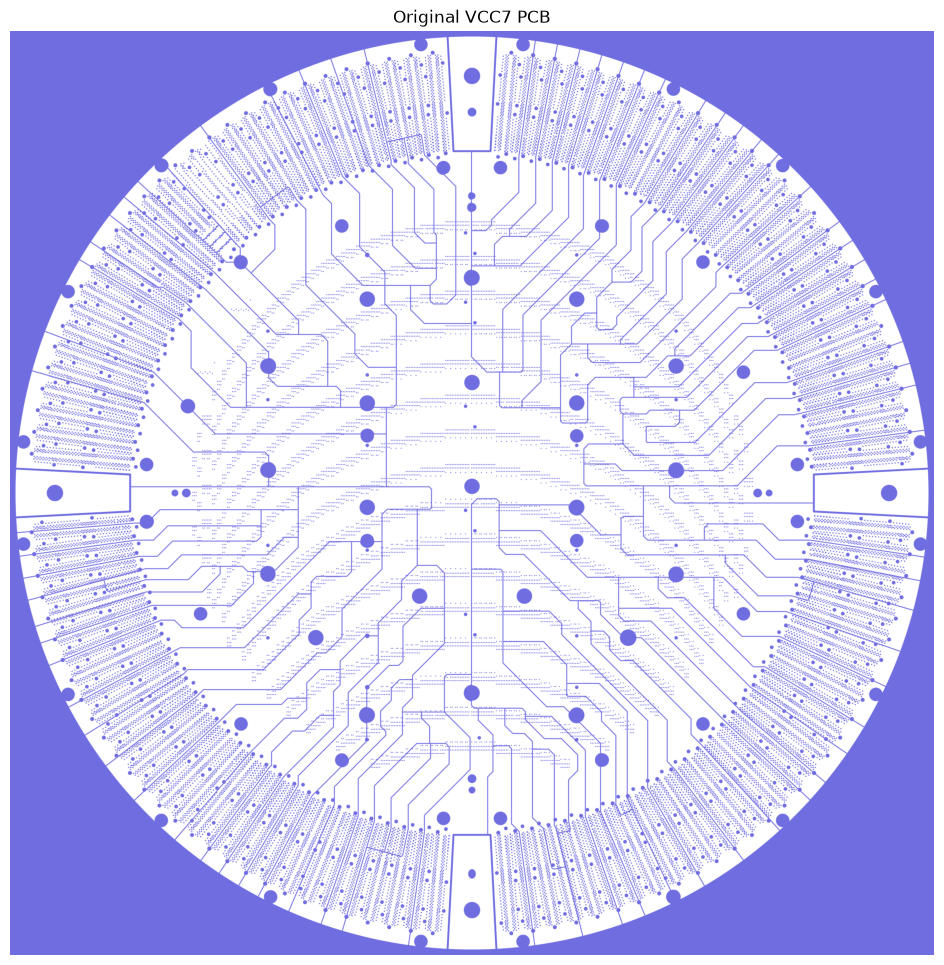

In [2]:
img_bgr = cv2.imread(str(IMAGE_PATH))

if img_bgr is None:
    raise FileNotFoundError(
        f"이미지를 찾을 수 없습니다: {IMAGE_PATH.resolve()}"
    )

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

height, width = img_rgb.shape[:2]

print(f"이미지 크기: {width} x {height}")

plt.imshow(img_rgb)
plt.title("Original VCC7 PCB")
plt.axis("off")
plt.show()

추출된 패턴 픽셀 수: 2085009


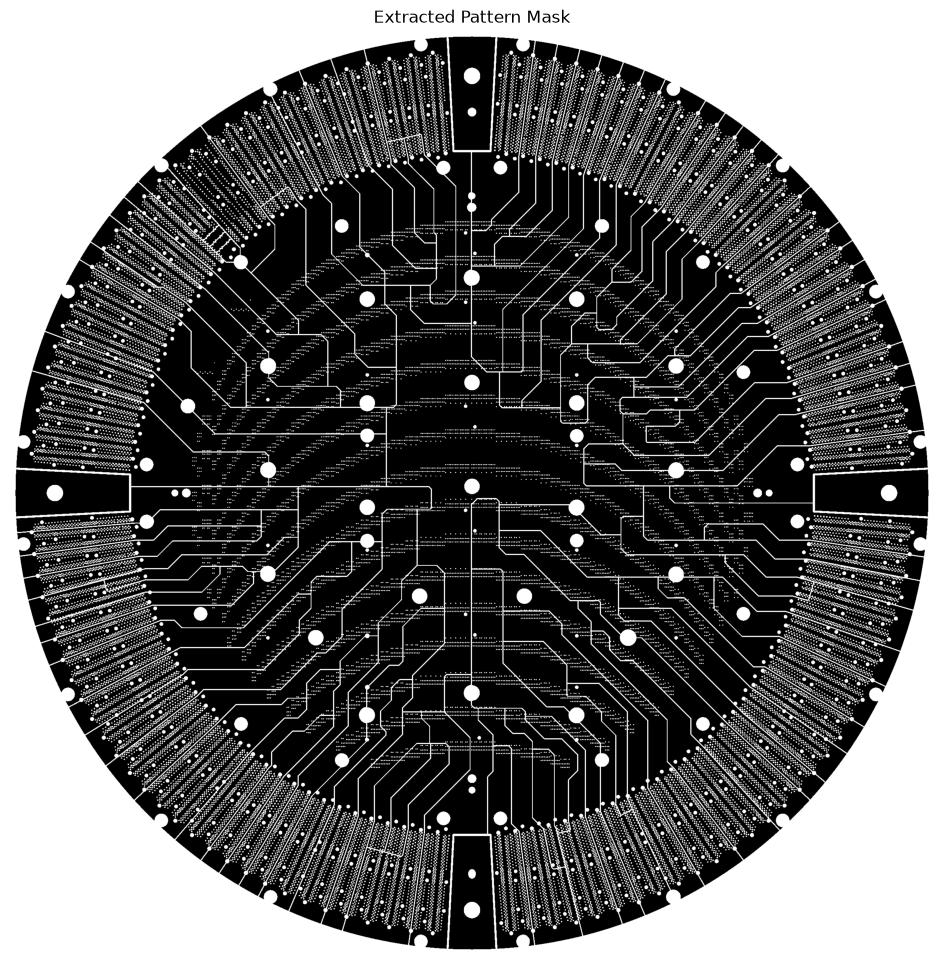

True

In [3]:
hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

# 보라색 영역 추출
lower_purple = np.array([105, 40, 40])
upper_purple = np.array([145, 255, 255])

mask = cv2.inRange(
    hsv,
    lower_purple,
    upper_purple
)

copper = mask > 0

print("추출된 패턴 픽셀 수:", np.sum(copper))

plt.imshow(copper, cmap="gray")
plt.title("Extracted Pattern Mask")
plt.axis("off")
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "copper_mask.png"),
    mask
)

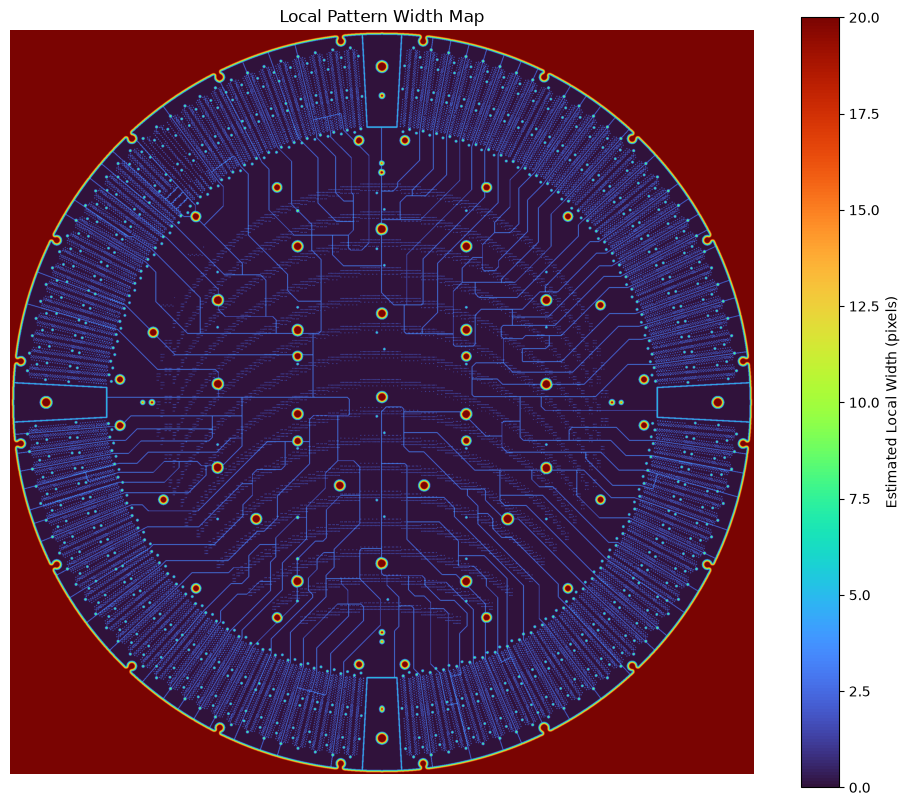

In [4]:
dist = cv2.distanceTransform(
    mask,
    cv2.DIST_L2,
    5
)

local_width = 2 * dist

plt.figure(figsize=(12, 10))
plt.imshow(
    local_width,
    cmap="turbo",
    vmin=0,
    vmax=20
)
plt.colorbar(label="Estimated Local Width (pixels)")
plt.title("Local Pattern Width Map")
plt.axis("off")
plt.show()

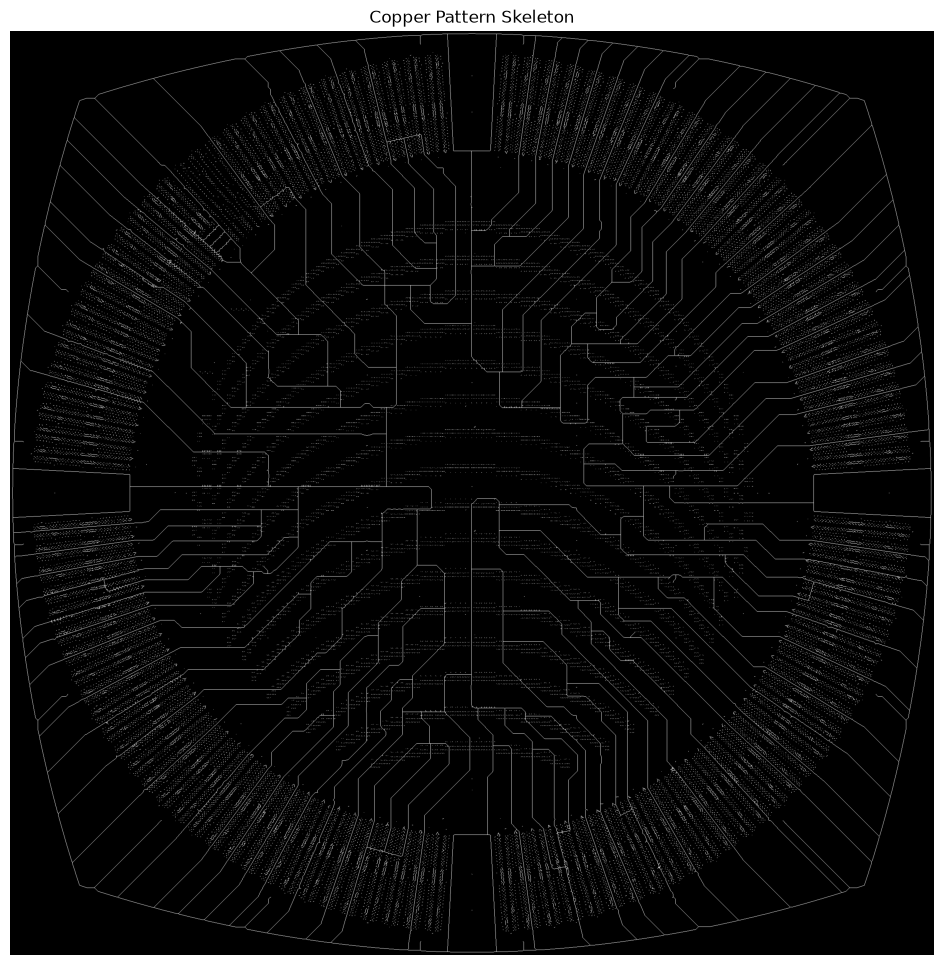

Skeleton 픽셀 수: 168496


In [5]:
skeleton = skeletonize(copper)

plt.figure(figsize=(12, 12))
plt.imshow(skeleton, cmap="gray")
plt.title("Copper Pattern Skeleton")
plt.axis("off")
plt.show()

print("Skeleton 픽셀 수:", np.sum(skeleton))

병목 후보 픽셀 수: 147628


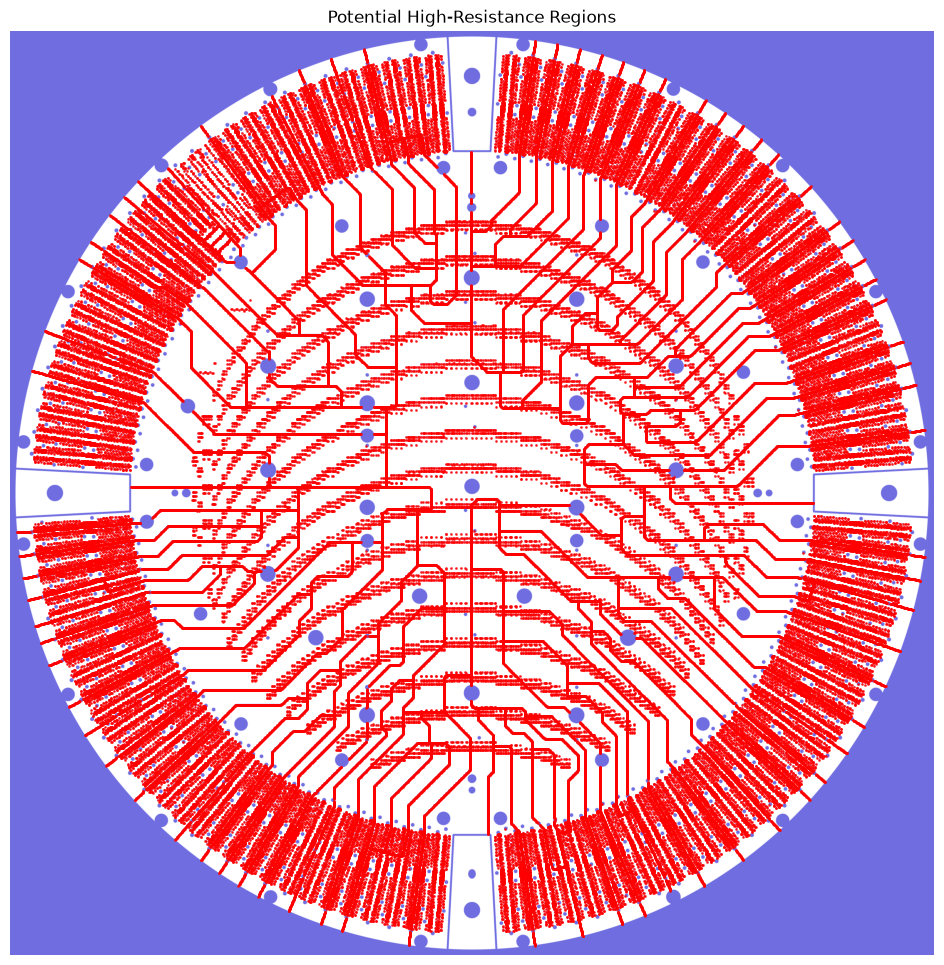

In [6]:
# 폭 기준 (픽셀)
WIDTH_THRESHOLD = 5.0

candidate_mask = (
    skeleton &
    (local_width > 0) &
    (local_width < WIDTH_THRESHOLD)
)

ys, xs = np.where(candidate_mask)

print("병목 후보 픽셀 수:", len(xs))

plt.figure(figsize=(12, 12))
plt.imshow(img_rgb)

plt.scatter(
    xs, ys,
    s=1,
    c="red",
    alpha=0.7
)

plt.title("Potential High-Resistance Regions")
plt.axis("off")
plt.show()

In [8]:
import time
import numpy as np
import pandas as pd
import cv2

start = time.time()

# 1. 후보 영역 연결 성분 분석
num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        candidate_mask.astype(np.uint8),
        connectivity=8
    )
)

# 2. 후보 픽셀의 좌표와 영역 번호 추출
ys, xs = np.where(labels > 0)
region_ids = labels[ys, xs]
widths = local_width[ys, xs]

# 3. 최소 폭을 가진 픽셀부터 정렬
order = np.argsort(widths)

# 4. 영역별 최소 폭 위치만 추출
sorted_regions = region_ids[order]

_, first_indices = np.unique(
    sorted_regions,
    return_index=True
)

selected = order[first_indices]

# 5. 작은 영역 제거
valid = stats[region_ids[selected], cv2.CC_STAT_AREA] >= 3
selected = selected[valid]

# 6. DataFrame 생성
df = pd.DataFrame({
    "x_pixel": xs[selected],
    "y_pixel": ys[selected],
    "min_width_px": widths[selected],
    "region_size": stats[
        region_ids[selected],
        cv2.CC_STAT_AREA
    ]
})

# 7. 최소 폭 기준 정렬
df = df.sort_values(
    "min_width_px",
    ascending=True
).reset_index(drop=True)

df.insert(
    0,
    "rank",
    np.arange(1, len(df) + 1)
)

print(f"검출 영역: {num_labels - 1}개")
print(f"유효 후보: {len(df)}개")
print(f"실행 시간: {time.time() - start:.2f}초")

display(df.head(20))

검출 영역: 33188개
유효 후보: 9194개
실행 시간: 0.08초


,rank,x_pixel,y_pixel,min_width_px,region_size
0,1,1369,2328,2.0,3
1,2,1311,74,2.0,13
2,3,1049,75,2.0,3
3,4,1080,75,2.0,3
4,5,1289,74,2.0,3
5,6,1319,75,2.0,3
6,7,1350,75,2.0,3
7,8,992,76,2.0,3
8,9,1021,76,2.0,3
9,10,1063,77,2.0,3


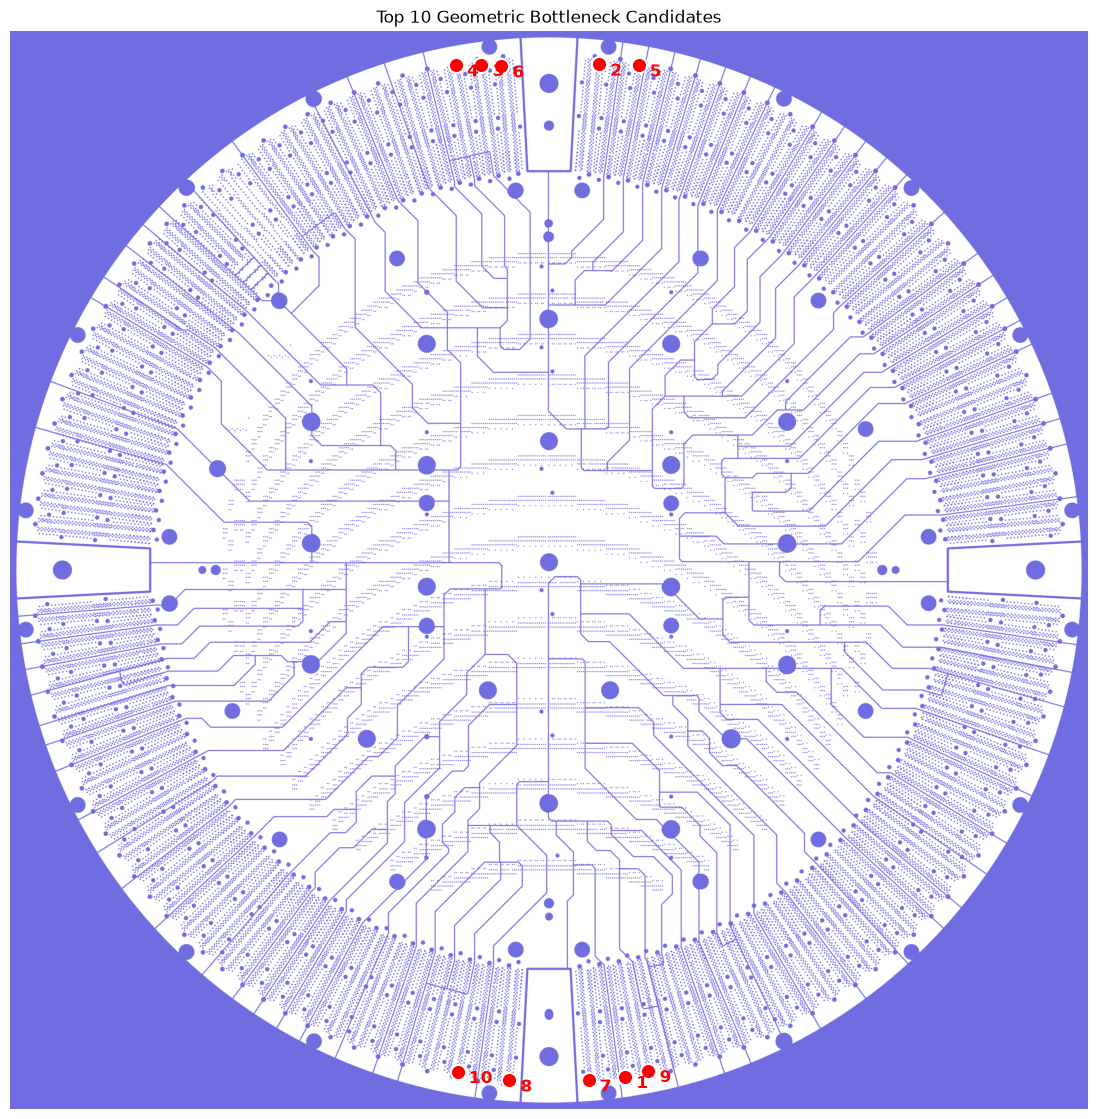

선정된 후보 수: 10
실행 시간: 3.72초


,rank,x_pixel,y_pixel,min_width_px,region_size
0,1,1369,2328,2.0,3
1,2,1311,74,2.0,13
2,3,1049,75,2.0,3
3,4,992,76,2.0,3
4,5,1399,76,2.0,3
5,6,1093,78,2.0,3
6,7,1288,2336,2.0,3
7,8,1111,2336,2.0,3
8,9,1421,2315,2.0,3
9,10,996,2317,2.0,3


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import time

start = time.time()

TOP_N = 10
MIN_DISTANCE = 40  # 후보 간 최소 거리 (pixel)

selected = []

for _, row in df.iterrows():

    x = int(row["x_pixel"])
    y = int(row["y_pixel"])

    # 기존 선정 후보와의 거리 확인
    too_close = any(
        np.hypot(
            x - p["x_pixel"],
            y - p["y_pixel"]
        ) < MIN_DISTANCE
        for p in selected
    )

    if not too_close:
        selected.append({
            "x_pixel": x,
            "y_pixel": y,
            "min_width_px": float(row["min_width_px"]),
            "region_size": int(row["region_size"])
        })

    if len(selected) >= TOP_N:
        break

# 최종 후보 DataFrame
top_df = pd.DataFrame(selected)

if not top_df.empty:
    top_df.insert(
        0,
        "rank",
        np.arange(1, len(top_df) + 1)
    )

# 시각화
fig, ax = plt.subplots(figsize=(14, 14))

ax.imshow(img_rgb)

for _, row in top_df.iterrows():

    x = int(row["x_pixel"])
    y = int(row["y_pixel"])
    rank = int(row["rank"])

    ax.scatter(
        x, y,
        s=120,
        c="red",
        edgecolors="white",
        linewidths=1.5
    )

    ax.annotate(
        str(rank),
        (x, y),
        xytext=(8, -8),
        textcoords="offset points",
        color="red",
        fontsize=12,
        fontweight="bold"
    )

ax.set_title("Top 10 Geometric Bottleneck Candidates")
ax.axis("off")

plt.savefig(
    OUTPUT_DIR / "top10_candidates.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"선정된 후보 수: {len(top_df)}")
print(f"실행 시간: {time.time()-start:.2f}초")

display(top_df)

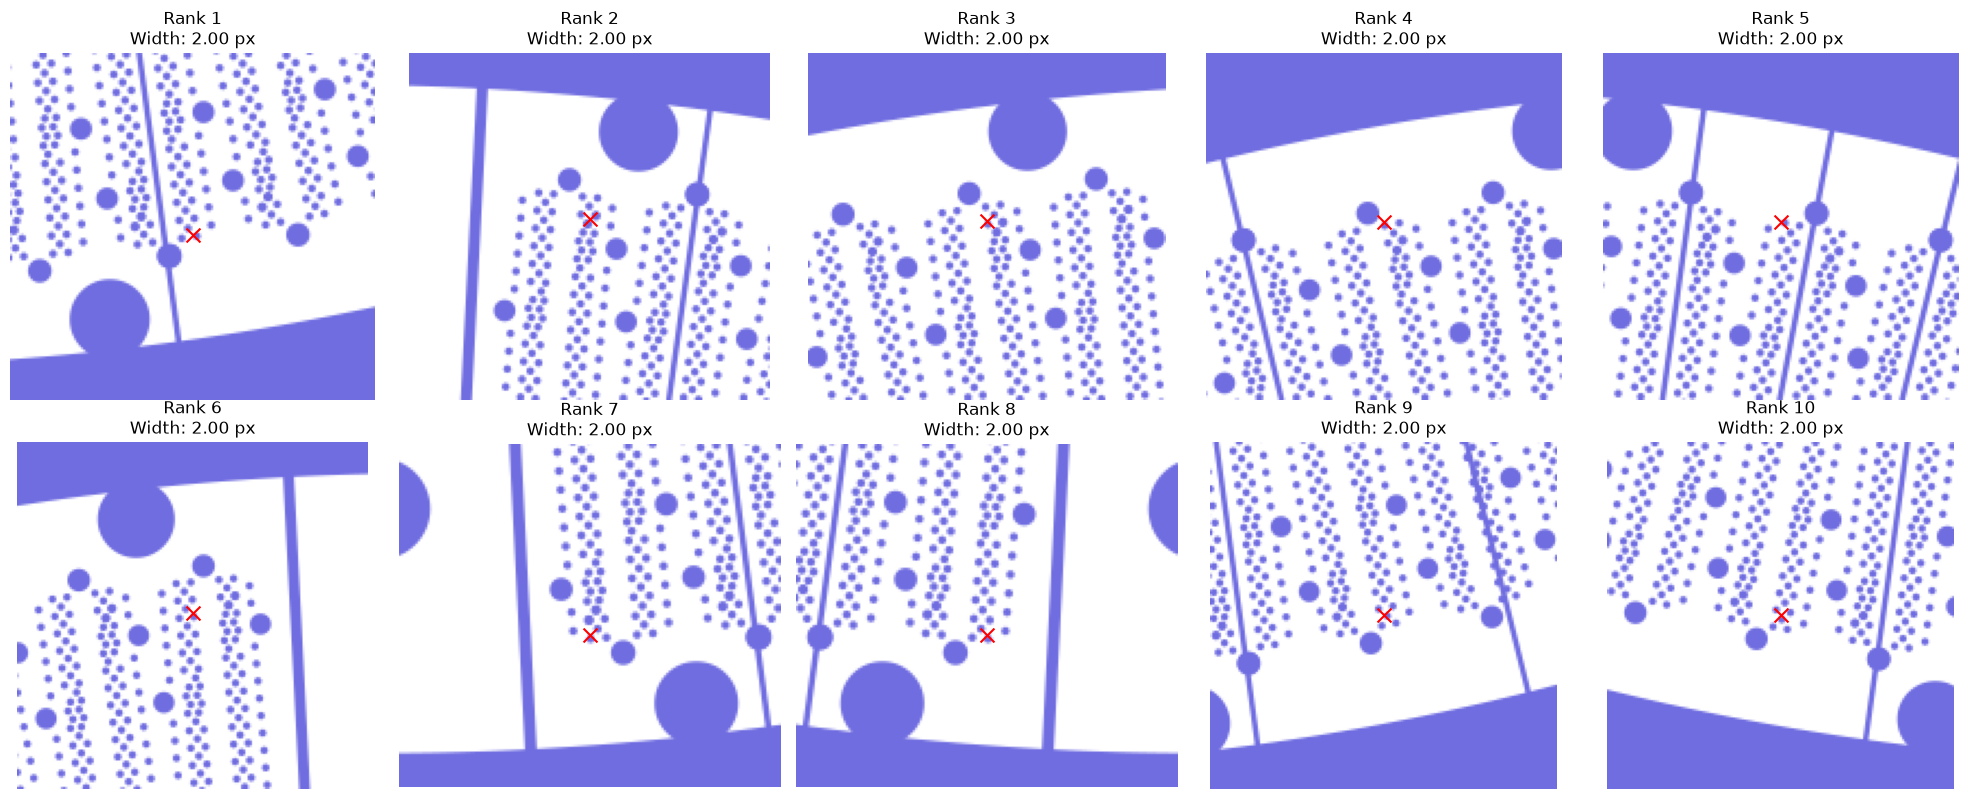

In [10]:
import math

CROP_SIZE = 80

n = len(top_df)

if n == 0:
    print("표시할 후보가 없습니다.")

else:
    cols = 5
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(20, 4 * rows),
        squeeze=False
    )

    for idx, (_, row) in enumerate(top_df.iterrows()):

        x = int(row["x_pixel"])
        y = int(row["y_pixel"])

        x1 = max(0, x - CROP_SIZE)
        x2 = min(width, x + CROP_SIZE)

        y1 = max(0, y - CROP_SIZE)
        y2 = min(height, y + CROP_SIZE)

        crop = img_rgb[y1:y2, x1:x2]

        ax = axes.flat[idx]

        ax.imshow(
            crop,
            extent=(x1, x2, y2, y1)
        )

        ax.scatter(
            x, y,
            c="red",
            marker="x",
            s=100
        )

        ax.set_title(
            f"Rank {int(row['rank'])}\n"
            f"Width: {row['min_width_px']:.2f} px"
        )

        ax.axis("off")

    # 남는 subplot 제거
    for idx in range(n, rows * cols):
        axes.flat[idx].axis("off")

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "top10_details.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

In [11]:
# Gerber 좌표 범위 (기존 변환 코드 기준)
X_MIN = -242.59
X_MAX = 242.59

Y_MIN = -242.59
Y_MAX = 242.59

# 이미지 좌표 → 실제 PCB 좌표
def pixel_to_mm(x, y):

    x_mm = X_MIN + (x / width) * (X_MAX - X_MIN)

    y_mm = Y_MAX - (y / height) * (Y_MAX - Y_MIN)

    return x_mm, y_mm


# 후보 좌표 변환
if not top_df.empty:

    coordinates = top_df.apply(
        lambda row: pixel_to_mm(
            row["x_pixel"],
            row["y_pixel"]
        ),
        axis=1
    )

    top_df["x_mm"] = [
        coord[0] for coord in coordinates
    ]

    top_df["y_mm"] = [
        coord[1] for coord in coordinates
    ]

    display(top_df)

,rank,x_pixel,y_pixel,min_width_px,region_size,x_mm,y_mm
0,1,1369,2328,2.0,3,34.164758,-228.034600
1,2,1311,74,2.0,13,22.439575,227.630283
2,3,1049,75,2.0,3,-30.525908,227.428125
3,4,992,76,2.0,3,-42.048933,227.225967
4,5,1399,76,2.0,3,40.229508,227.225967
5,6,1093,78,2.0,3,-21.630942,226.821650
6,7,1288,2336,2.0,3,17.789933,-229.651867
7,8,1111,2336,2.0,3,-17.992092,-229.651867
8,9,1421,2315,2.0,3,44.676992,-225.406542
9,10,996,2317,2.0,3,-41.240300,-225.810858


In [12]:
# 전체 후보 좌표 저장
df.to_csv(
    OUTPUT_DIR / "all_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)

# 상위 10개 후보 저장
top_df.to_csv(
    OUTPUT_DIR / "top10_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)

print("CSV 저장 완료")

print("\n저장된 파일:")
print("- all_candidates.csv")
print("- top10_candidates.csv")
print("- top10_candidates.png")
print("- top10_details.png")

CSV 저장 완료

저장된 파일:
- all_candidates.csv
- top10_candidates.csv
- top10_candidates.png
- top10_details.png


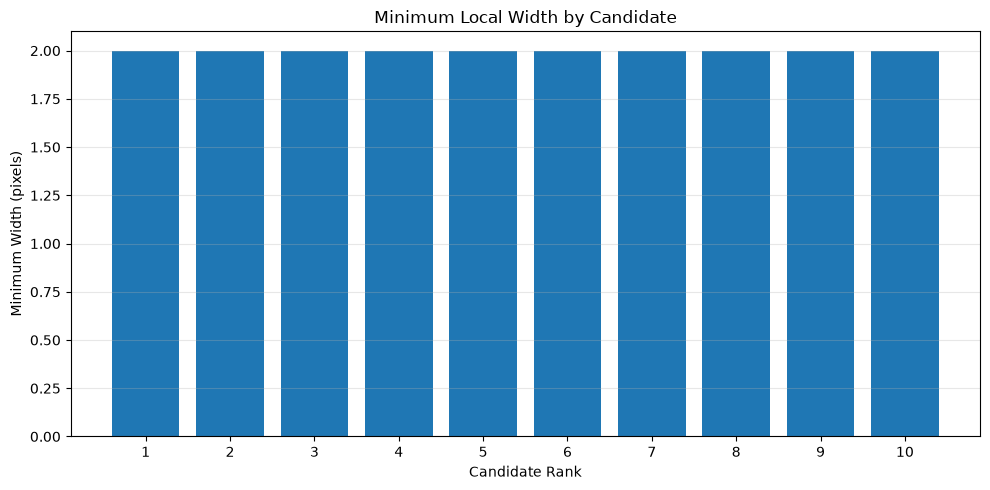

In [13]:
if not top_df.empty:

    fig, ax = plt.subplots(figsize=(10, 5))

    ranks = top_df["rank"].astype(str)

    ax.bar(
        ranks,
        top_df["min_width_px"]
    )

    ax.set_xlabel("Candidate Rank")
    ax.set_ylabel("Minimum Width (pixels)")
    ax.set_title("Minimum Local Width by Candidate")

    ax.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "width_comparison.png",
        dpi=200
    )

    plt.show()